# Final Model: Average of the Hybrid Model (v3) and the Machine-Learning Model

## 1. Objective and approach

**Objective.** For 12 unseen batches of a fed-batch cell culture, only the day-0 measurements and the complete feed and volume log are available. The task is to predict four quantities on each of 13 days: living-cell density (`vcd`), total-cell density (`tcd`), substrate (`substrate`) and byproduct (`byproduct`). This gives 12 x 13 = 156 rows. The evaluation metric is the mean absolute percentage error (MAPE), computed per variable and averaged over the four variables (lower is better).

**Models.**
- **Baseline.** The per-day mean curve of the known batches.
- **ML model.** A data-driven model that predicts the relative deviation of a batch from the baseline. It combines a ridge regression, a gradient-boosted tree model (XGBoost) and a per-day ridge regression, and uses two input features derived from the volume and feed log (soft sensors).
- **v3.** The hybrid model developed by the teammates (branch `hybrid_v3_tr`): a mechanistic ODE with a neural-network correction, followed by soft-sensor corrections and a blend with a gradient-boosting model. Its predictions are read from the files it produced.
- **Final model.** The **average of v3 and ML**: for every batch, day and variable, the geometric mean of the two predictions with equal weights.

**Procedure.** (1) data and split, (2) feature table, (3) soft sensors, (4) models, (5) cross-validation of the ML model, (6) comparison with v3 on the folds used for v3, (7) final training and prediction, (8) averaging and format checks, (9) visual checks. No file is submitted to the leaderboard by this notebook.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from xgboost import XGBRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TARGETS = ["vcd", "tcd", "substrate", "byproduct"]
FEEDS = ["feed_substrate", "feed_b", "feed_c", "feed_d"]
EXT = ROOT / "outputs" / "external_v3"                       # prediction files of v3 (copied from the teammates' branch; not committed)
V3_OOF = Path(os.environ.get("V3_OOF", EXT / "v3_oof_predictions.csv"))   # v3 out-of-fold predictions (49 batches, 7 folds)
V3_SUB = Path(os.environ.get("V3_SUB", EXT / "v3_submission.csv"))        # v3 predictions for the 12 test batches
OUT = ROOT / "outputs" / "ml"
OUT.mkdir(parents=True, exist_ok=True)

## 2. Data and validation design

**Data.** `bioreaction_remaining.csv` contains one row per event: a measurement (cell densities, substrate, byproduct and culture volume) or a feed addition. There are 61 batches: 49 with measurements on all days and 12 test batches for which only the day-0 measurement and the feeds are given.

**Split.** The split is fixed for the whole team (`outputs/splits.csv`):

| group | batches | use |
|---|---|---|
| `dev` | 39 | model development and 5-fold cross-validation |
| `holdout` | 10 | not used for any decision in this notebook |
| `test` | 12 | prediction targets |

**Cross-validation.** Each fold of about 8 batches is predicted by a model trained on the remaining folds. Splitting is always by whole batch, because the rows of one batch are strongly correlated. Every quantity derived from data (mean curve, soft-sensor constants, model parameters) is computed from the training batches of the fold only.

In [2]:
def build_table(df):
    rows = []
    for b, g in df.groupby("batch_id"):
        g = g.sort_values("elapsed_time")
        samples = g[g.volume.notna()]
        d0 = samples.iloc[0]
        feeds = g[g[FEEDS].notna().any(axis=1)]
        times = samples.elapsed_time.values
        for i in range(1, len(samples)):
            s = samples.iloc[i]
            t = s.elapsed_time
            t_next = times[i + 1] if i + 1 < len(times) else np.inf
            before = feeds[feeds.elapsed_time < t]
            last_day = before[before.elapsed_time >= t - 1]
            after = feeds[(feeds.elapsed_time >= t) & (feeds.elapsed_time < t_next)]
            r = dict(batch_id=b, elapsed_time=t, day=t, vcd0=d0.vcd, viability0=d0.vcd / d0.tcd,
                     substrate0=d0.substrate, byproduct0=d0.byproduct, volume0=d0.volume)
            for f in FEEDS:
                r[f"cum_{f}"] = before[f].sum()
                r[f"last24h_{f}"] = last_day[f].sum()
                r[f"next_{f}"] = after[f].sum()
            for c in TARGETS:
                r[c] = s[c]
            rows.append(r)
    return pd.DataFrame(rows)


raw = pd.read_csv(ROOT / "data" / "bioreaction_remaining.csv")
tab = build_table(raw)
splits = pd.read_csv(ROOT / "outputs" / "splits.csv")
tab = tab.merge(splits[["batch_id", "role", "fold"]], on="batch_id", how="left")
FEATURES = ["day", "vcd0", "viability0", "substrate0", "byproduct0", "volume0"] + \
           [f"{p}_{f}" for f in FEEDS for p in ("cum", "last24h", "next")]

# batch-level information from the logs
BAT = {}
for b, g in raw.groupby("batch_id"):
    g = g.sort_values("elapsed_time")
    st = g[g.volume.notna()]
    t, V = st.elapsed_time.values, st.volume.values                        # 14 stamps: day 0..13
    fe = g[g[FEEDS].notna().any(axis=1)]
    cum = np.array([fe.loc[fe.elapsed_time < ti, FEEDS].sum().sum() for ti in t])
    fs = g[g.feed_substrate.notna()]
    bol = lambda lo, hi, vref: fs.loc[(fs.elapsed_time >= lo) & (fs.elapsed_time < hi), "feed_substrate"].sum() / vref
    BAT[b] = dict(resid=V - V[0] - cum,                                    # volume not explained by the logged feeds
                  A11=bol(11, 12, V[11]), A12=bol(12, 13, V[12]), A_early=bol(6, 11, V[8]),
                  tot_sub=fs.feed_substrate.sum(), tot_b=g.feed_b.sum(), tot_c=g.feed_c.sum(), tot_d=g.feed_d.sum())
print(len(BAT), "batches with log information")

61 batches with log information


## 3. Feature table

The event log is transformed into a table with one row per batch and sampling day (day 1 to 13). Each row contains the following inputs, all of which are available for test batches:

- **time**: the sampling day;
- **initial state**: living-cell density, viability (living / total cells), substrate, byproduct and volume at day 0;
- **feeds**: for each of the four feeds, the cumulative amount added before the sample, the amount added in the preceding 24 h, and the amount added between this sample and the next.

The row also holds the four measured values (the targets), which are empty for test batches. No measurement taken after day 0 is used as an input.

## 4. Soft sensors derived from the volume and feed log

Two quantities are extracted from the log. Both were identified by the authors of v3 and are re-implemented here.

**Soft sensor 1: unexplained volume (indicator of byproduct formation).** The culture volume is logged at every sample. It is expected to equal the initial volume plus the logged feeds, minus the volume removed by sampling (a constant loss per sample, about 0.05 L, identical across batches). After this loss is added back, the residual volume is attributed to pH-control base added by the bioreactor. Base addition is expected to increase with acid production, hence with byproduct (lactate) formation. The derived inputs are the cumulative residual up to the current day, the residuals at days 3, 4 and 5, and the mean residual over days 6 to 13, each relative to the level at days 1 and 2.

**Soft sensor 2: bolus size (indicator of substrate level).** Substrate boluses are added when the substrate concentration is low, so a larger bolus per culture volume indicates a lower concentration beforehand. The derived inputs are the bolus size per culture volume around day 11, around day 12, and in days 6 to 11.

The table below shows the residual volume by day (mean and standard deviation over batches). The common linear decline is the sampling loss; the information resides in the batch-to-batch differences.

In [3]:
lab_ids = splits[splits.role.isin(["dev", "holdout"])].batch_id
R = np.array([BAT[b]["resid"] for b in lab_ids])
pd.DataFrame({"mean": R.mean(0), "std over batches": R.std(0)}, index=pd.Index(range(14), name="day")).round(3).T

day,0,1,2,3,4,5,6,7,8,9,10,11,12,13
mean,0.0,-0.019,-0.036,0.005,0.002,-0.026,-0.072,-0.124,-0.184,-0.233,-0.284,-0.334,-0.381,-0.433
std over batches,0.0,0.010,0.011,0.017,0.022,0.025,0.025,0.023,0.026,0.025,0.024,0.025,0.026,0.026


In [4]:
def sensors(train_batches):
    # sample removal per stamp, estimated from late culture (days 8-13) of the TRAINING batches only
    sv = -np.median([(BAT[b]["resid"][13] - BAT[b]["resid"][8]) / 5 for b in train_batches])
    out = {}
    for b, d in BAT.items():
        A = d["resid"] + np.arange(14) * sv                                # sample removal added back
        base = A[1:3].mean()                                               # early level (days 1-2)
        out[b] = dict(base_all=A - base, base_to3=A[3] - base, base_to4=A[4] - base, base_to5=A[5] - base,
                      base_tot=A[6:14].mean() - base, A11=d["A11"], A12=d["A12"], A_early=d["A_early"])
    return out


VOL = ["base_cum", "base_to3", "base_to4", "base_to5", "base_tot"]
BOL = ["A11", "A12", "A_early"]


def attach(rows, sens):
    r = rows.copy()
    r["dayi"] = r.elapsed_time.round().astype(int)
    r["base_cum"] = [sens[b]["base_all"][d] for b, d in zip(r.batch_id, r.dayi)]
    for k in VOL[1:] + BOL:
        r[k] = [sens[b][k] for b in r.batch_id]
    for k in ["tot_sub", "tot_b", "tot_c", "tot_d"]:
        r[k] = [BAT[b][k] for b in r.batch_id]
    return r

## 5. ML model

**Target definition.** The models do not predict the raw values. They predict `log(value / mean curve)`, the relative deviation from the per-day geometric-mean curve of the training batches (for example, +0.04 corresponds to about 4 % above the mean curve). The prediction is `mean curve x exp(model output)`. This formulation matches the percentage-error metric and removes the common time course from the learning problem.

**Components.**
1. **Ridge regression** (row level): linear model on standardized inputs; the regularization strength is selected by internal cross-validation.
2. **XGBoost** (row level): 400 trees, learning rate 0.03, maximum depth 3, minimum child weight 3, row and column subsampling of 0.8.
3. **Per-day ridge regression**: a separate ridge model for every variable and every day, using batch-level inputs (initial state, feed totals and the soft sensors).

**ML model** = geometric mean of (the average of ridge and XGBoost at row level) and (the per-day ridge).

In [5]:
def mean_curve(train, t):
    m = np.exp(np.log(train[TARGETS]).groupby(train.dayi).mean())
    return np.column_stack([np.interp(t, m.index.values, m[c].values) for c in TARGETS])


def make(kind):
    if kind == "ridge":
        return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 30)))
    return XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=3, min_child_weight=3, subsample=0.8,
                        colsample_bytree=0.8, objective="reg:squarederror", n_jobs=4, random_state=0)


def blend_pred(train, new, feats):
    """ridge + XGBoost on every row (day as a feature)."""
    btr, bnew = mean_curve(train, train.elapsed_time), mean_curve(train, new.elapsed_time)
    out = []
    for j, c in enumerate(TARGETS):
        y = np.log(train[c].values / btr[:, j])
        mu = np.mean([make(k).fit(train[feats], y).predict(new[feats]) for k in ("ridge", "xgb")], axis=0)
        out.append(bnew[:, j] * np.exp(mu))
    return np.column_stack(out)


PERDAY = ["vcd0", "viability0", "substrate0", "byproduct0", "volume0", "tot_sub", "tot_b", "tot_c", "tot_d"] + \
         VOL + BOL


def perday_pred(train, new):
    """one ridge per variable and per day, on batch-level information."""
    btr, bnew = mean_curve(train, train.elapsed_time), mean_curve(train, new.elapsed_time)
    out = np.zeros((len(new), 4))
    for day in range(1, 14):
        mt, mn = (train.dayi == day).values, (new.dayi == day).values
        if not mn.any():
            continue
        for j, c in enumerate(TARGETS):
            y = np.log(train.loc[mt, c].values / btr[mt, j])
            m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 30))).fit(train.loc[mt, PERDAY], y)
            out[mn, j] = bnew[mn, j] * np.exp(m.predict(new.loc[mn, PERDAY]))
    return out


def mape(obs, pred):
    s = 100 * np.mean(np.abs((obs - pred) / obs), axis=0)
    return np.append(s, s.mean())


NAMES = ["base", "+ volume sensor", "+ bolus sensor", "+ both sensors", "per-day ridge", "avg(both, per-day)"]


def evaluate(lab, fold_col):
    res = {k: [] for k in NAMES}
    oof = []
    for f in sorted(lab[fold_col].unique()):
        trn = lab[lab[fold_col] != f]
        sens = sensors(trn.batch_id.unique())
        tr, va = attach(trn, sens).reset_index(drop=True), attach(lab[lab[fold_col] == f], sens).reset_index(drop=True)
        P = {"base": blend_pred(tr, va, FEATURES),
             "+ volume sensor": blend_pred(tr, va, FEATURES + VOL),
             "+ bolus sensor": blend_pred(tr, va, FEATURES + BOL),
             "+ both sensors": blend_pred(tr, va, FEATURES + VOL + BOL),
             "per-day ridge": perday_pred(tr, va)}
        P["avg(both, per-day)"] = np.exp((np.log(P["+ both sensors"]) + np.log(P["per-day ridge"])) / 2)
        for k in NAMES:
            res[k].append(mape(va[TARGETS].values, P[k]))
        o = va[["batch_id", "dayi"]].copy()
        for k in ["+ both sensors", "avg(both, per-day)"]:
            for j, c in enumerate(TARGETS):
                o[f"{k}|{c}"] = P[k][:, j]
        oof.append(o)
    return {k: np.array(v) for k, v in res.items()}, pd.concat(oof)


def table(res):
    base = res["base"][:, -1]
    rows = []
    for k, v in res.items():
        d = v[:, -1] - base
        rows.append([k] + list(v.mean(0).round(2)) + [f"{d.mean():+.2f} +/- {d.std(ddof=1):.2f}"])
    return pd.DataFrame(rows, columns=["variant"] + TARGETS + ["average", "vs base (paired)"]).set_index("variant")

## 6. Cross-validation of the ML model (39 dev batches, 5 folds)

Three configurations are compared on batches not used for training:

1. **mean curve**: baseline without learning;
2. **ML model without soft sensors**: row-level ridge + XGBoost with the 18 table inputs;
3. **ML model with soft sensors**: the final ML model described above.

The error is the percentage error averaged over the four variables.

In [6]:
def mape(obs, pred):
    s = 100 * np.mean(np.abs((obs - pred) / obs), axis=0)
    return np.append(s, s.mean())


def ml_model(tr, va):
    """ML model with soft sensors: geometric mean of the row-level (ridge + XGBoost) model and the per-day ridge."""
    p_row = blend_pred(tr, va, FEATURES + VOL + BOL)
    p_day = perday_pred(tr, va)
    return np.exp((np.log(p_row) + np.log(p_day)) / 2)


def run_cv(lab, fold_col):
    res = {"mean curve": [], "ML model without soft sensors": [], "ML model with soft sensors": []}
    for f in sorted(lab[fold_col].unique()):
        trn = lab[lab[fold_col] != f]
        sens = sensors(trn.batch_id.unique())                      # all quantities are derived from the training batches only
        tr = attach(trn, sens).reset_index(drop=True)
        va = attach(lab[lab[fold_col] == f], sens).reset_index(drop=True)
        obs = va[TARGETS].values
        res["mean curve"].append(mape(obs, mean_curve(tr, va.elapsed_time)))
        res["ML model without soft sensors"].append(mape(obs, blend_pred(tr, va, FEATURES)))
        res["ML model with soft sensors"].append(mape(obs, ml_model(tr, va)))
    return {k: np.array(v) for k, v in res.items()}


devrows = tab[tab.role == "dev"].copy()
cvA = run_cv(devrows, "fold")
rows = []
for k, v in cvA.items():
    rows.append([k] + list(v.mean(0).round(2)) + [round(v[:, -1].std(ddof=1), 2)])
pd.DataFrame(rows, columns=["model"] + TARGETS + ["average error (%)", "std over folds"]).set_index("model")

,vcd,tcd,substrate,byproduct,average error (%),std over folds
model,,,,,,
mean curve,8.63,8.66,11.97,12.90,10.54,0.89
ML model without soft sensors,7.17,7.07,11.15,11.57,9.24,0.87
ML model with soft sensors,7.39,7.30,9.43,8.63,8.19,0.78


**Results** *(values at the time of writing)*. The mean curve has an average error of about 10.5 %. The ML model without soft sensors reaches about 9.2 %, and the ML model with soft sensors about 8.2 %. The improvement is concentrated in `byproduct` (about 11.6 % to 8.6 %), consistent with the role of the unexplained-volume sensor, and in `substrate` (about 11.2 % to 9.4 %). The standard deviation over folds (about 1 percentage point) quantifies the sampling noise; differences between configurations of less than this magnitude are not conclusive on their own.

## 7. Comparison with v3 on the validation folds of v3

v3 was validated by 7-fold grouped cross-validation over all 49 known batches. For a like-for-like comparison, the ML model is evaluated on exactly these folds (the fold assignment is read from the out-of-fold file of v3). This comparison is descriptive; no model choice was made on it.

In [7]:
if V3_OOF.exists():
    t3 = pd.read_csv(V3_OOF)
    fold_of = t3.drop_duplicates("batch_id").set_index("batch_id").fold
    allrows = tab[tab.role.isin(["dev", "holdout"])].copy()
    allrows["foldB"] = allrows.batch_id.map(fold_of)
    oofB = []
    for f in sorted(allrows.foldB.unique()):
        trn = allrows[allrows.foldB != f]
        sens = sensors(trn.batch_id.unique())
        tr = attach(trn, sens).reset_index(drop=True)
        va = attach(allrows[allrows.foldB == f], sens).reset_index(drop=True)
        p = ml_model(tr, va)
        o = va[["batch_id", "dayi"]].copy()
        for j, c in enumerate(TARGETS):
            o[f"ml_{c}"] = p[:, j]
        oofB.append(o)
    oofB = pd.concat(oofB)
    th = t3.rename(columns={"day": "dayi"})[["batch_id", "dayi"] + [f"v3 final (50/50 blend)|{c}" for c in TARGETS] + [f"obs_{c}" for c in TARGETS]]
    m = oofB.merge(th, on=["batch_id", "dayi"])
    assert len(m) == 637
    obs = m[[f"obs_{c}" for c in TARGETS]].values
    ml_oof = m[[f"ml_{c}" for c in TARGETS]].values
    v3_oof = m[[f"v3 final (50/50 blend)|{c}" for c in TARGETS]].values
    cmp_ = pd.DataFrame({"v3": mape(obs, v3_oof), "ML model": mape(obs, ml_oof),
                         "average of v3 and ML": mape(obs, np.exp((np.log(ml_oof) + np.log(v3_oof)) / 2))},
                        index=TARGETS + ["average"]).round(2)
    display(cmp_)
else:
    print("out-of-fold file of v3 not found:", V3_OOF)

,v3,ML model,average of v3 and ML
vcd,6.97,6.85,6.74
tcd,6.95,6.77,6.69
substrate,8.02,8.90,8.05
byproduct,8.76,8.29,8.33
average,7.67,7.70,7.45


**Results** *(values at the time of writing)*. On these folds v3 reaches 7.67 % and the ML model 7.70 %, i.e. comparable performance. The error profiles differ by variable: the ML model is more accurate for `vcd`, `tcd` and `byproduct` (6.85 / 6.77 / 8.29 against 6.97 / 6.95 / 8.76), whereas v3 is considerably more accurate for `substrate` (8.02 against 8.90). Because the errors of the two models are only partially correlated, their average has a lower error (**7.45 %**) than either model.

Limitations: the difference of about 0.2 percentage points is small relative to the variation of scores between sets of batches; the score of v3 is slightly optimistic because its final design steps were chosen on these folds (as stated by its authors).

## 8. Final training and prediction of the test batches

The ML model is trained on all 49 known batches; the constants of the volume sensor are re-estimated on these batches. The 12 test batches are then predicted from their day-0 values, feeds and volume log, in the same way as the validation batches.

In [8]:
labelled = tab[tab.role.isin(["dev", "holdout"])]
test = tab[tab.role == "test"]
assert labelled.batch_id.nunique() == 49 and test.batch_id.nunique() == 12

sens = sensors(labelled.batch_id.unique())
tr_all = attach(labelled, sens).reset_index(drop=True)
te = attach(test, sens).reset_index(drop=True)
ml_pred = ml_model(tr_all, te)
print("ML predictions for the test batches:", ml_pred.shape)

ML predictions for the test batches: (156, 4)


## 9. Average of v3 and ML, and format checks

Each row of the template (`bioreaction_template.csv`) is matched to the prediction of the same batch at the nearest sampling time.

**Averaging.** For every batch, day and variable, the final prediction is the weighted geometric mean `ML^w x v3^(1-w)`. The weight `W_ML` is set to 0.5 for all variables (equal weights). Validation suggested slightly different weights per variable (about 0.5 for the cell densities, 0.25 for substrate and 0.75 for byproduct), but the expected gain is only about 0.05 percentage points and the weights would be selected on the same predictions that are used to evaluate them. Equal weights are therefore retained.

The result is written only if all format checks pass: 156 rows, columns and row order identical to the template, no missing values and all values positive.

In [9]:
tpl = pd.read_csv(ROOT / "data" / "bioreaction_template.csv")


def to_template(batches, times, values):
    p = pd.DataFrame(values, columns=TARGETS)
    p.insert(0, "elapsed_time", times)
    p.insert(0, "batch_id", batches)
    rows, used = [], set()
    for _, r in tpl.iterrows():
        q = p[p.batch_id == r.batch_id]
        i = (q.elapsed_time - r.elapsed_time).abs().idxmin()
        used.add(i)
        rows.append([r.batch_id, r.elapsed_time, *q.loc[i, TARGETS]])
    assert len(used) == len(tpl), "a prediction was used twice"
    return pd.DataFrame(rows, columns=tpl.columns)


def check(df, name):
    assert list(df.columns) == list(tpl.columns) and len(df) == 156, name
    assert not df[TARGETS].isna().any().any(), f"{name}: missing value"
    assert (df[TARGETS] > 0).all().all(), f"{name}: non-positive value"
    assert (df.batch_id == tpl.batch_id).all() and np.allclose(df.elapsed_time, tpl.elapsed_time), f"{name}: row order differs from the template"


ml_df = to_template(te.batch_id.values, te.elapsed_time.values, ml_pred)
check(ml_df, "ML model")
ml_df.to_csv(OUT / "submission_ml_model.csv", index=False)
print("ML model: format checks passed ->", OUT / "submission_ml_model.csv")

W_ML = {"vcd": 0.5, "tcd": 0.5, "substrate": 0.5, "byproduct": 0.5}      # weight of the ML model per variable

if V3_SUB.exists():
    v3_df = pd.read_csv(V3_SUB)
    check(v3_df, "v3")
    final = tpl.copy()
    for c in TARGETS:
        w = W_ML[c]
        final[c] = np.exp(w * np.log(ml_df[c].values) + (1 - w) * np.log(v3_df[c].values))
    check(final, "average of v3 and ML")
    final.to_csv(OUT / "submission_average_v3_ml.csv", index=False)
    print("Average of v3 and ML: format checks passed (156 rows, template order, no missing values, all positive) ->",
          OUT / "submission_average_v3_ml.csv")
    print("Rows with total cells below living cells:", int((final.tcd < final.vcd).sum()), "of 156")
else:
    final = None
    print("prediction file of v3 not found; only the ML model was written:", V3_SUB)

ML model: format checks passed -> C:\Users\user\Downloads\SDSC-STEM4Health-group15\outputs\ml\submission_ml_model.csv
Average of v3 and ML: format checks passed (156 rows, template order, no missing values, all positive) -> C:\Users\user\Downloads\SDSC-STEM4Health-group15\outputs\ml\submission_average_v3_ml.csv
Rows with total cells below living cells: 0 of 156


## 10. Visual checks

**Upper row.** Each point is one prediction (batch and day). Perfect agreement between ML and v3 would place all points on the dashed diagonal. The points follow the diagonal closely; the larger deviations occur mainly for `substrate` and for small `byproduct` values at late times, i.e. in the regions where the averaging is expected to be useful.

**Lower row.** Predictions for Batch54, the test batch with the lowest initial substrate value. The averaged prediction follows the expected time course and lies between the two models.

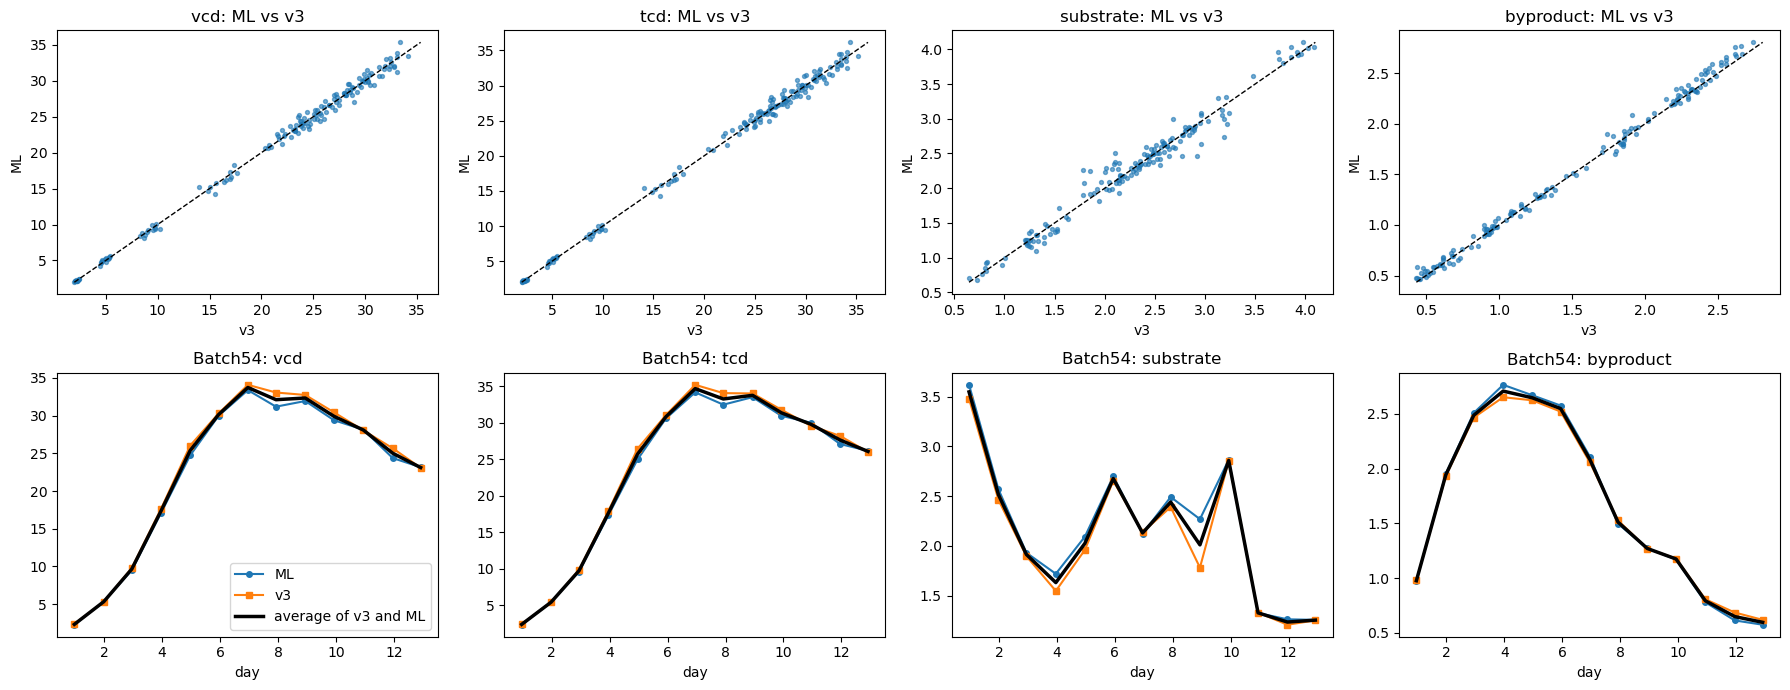

,vcd,tcd,substrate,byproduct
mean difference ML vs v3 (%),2.6,2.6,4.6,3.5
largest difference (%),9.2,9.2,27.3,32.5


In [10]:
import matplotlib.pyplot as plt

if final is not None:
    fig, ax = plt.subplots(2, 4, figsize=(18, 7))
    for j, c in enumerate(TARGETS):
        a = ax[0, j]
        a.scatter(v3_df[c], ml_df[c], s=8, alpha=.6)
        lo, hi = min(v3_df[c].min(), ml_df[c].min()), max(v3_df[c].max(), ml_df[c].max())
        a.plot([lo, hi], [lo, hi], "k--", lw=1)
        a.set_title(f"{c}: ML vs v3"); a.set_xlabel("v3"); a.set_ylabel("ML")
        b = tpl.batch_id == "Batch54"
        a = ax[1, j]
        a.plot(tpl.elapsed_time[b], ml_df[c][b], "o-", color="tab:blue", label="ML", ms=4)
        a.plot(tpl.elapsed_time[b], v3_df[c][b], "s-", color="tab:orange", label="v3", ms=4)
        a.plot(tpl.elapsed_time[b], final[c][b], "-", color="k", lw=2.5, label="average of v3 and ML")
        a.set_title(f"Batch54: {c}"); a.set_xlabel("day")
    ax[1, 0].legend()
    plt.tight_layout(); plt.savefig(OUT / "final_checks.png", dpi=110); plt.show()
    diff = pd.DataFrame({c: [100 * np.mean(np.abs(ml_df[c] - v3_df[c]) / v3_df[c]),
                             100 * np.max(np.abs(ml_df[c] - v3_df[c]) / v3_df[c])] for c in TARGETS},
                        index=["mean difference ML vs v3 (%)", "largest difference (%)"]).round(1)
    display(diff)

## 11. Summary, limitations and references

**Summary.** The ML model predicts the relative deviation of a batch from the per-day mean curve, using the initial state, the feeds and two soft sensors derived from the volume and feed log. In cross-validation on batches not used for training, the average error decreases from about 10.5 % (mean curve) to about 8.2 % (ML model). On the validation folds of v3, the ML model (7.70 %) and v3 (7.67 %) perform comparably, and the average of v3 and ML (7.45 %) outperforms both. The final model is the average of v3 and ML.

**Limitations.**
- The soft sensors use the complete feed and volume log, including events after the prediction time. This is permitted for the 12 test batches, whose full logs are provided, but the model cannot be used as a real-time forecaster.
- With 12 test batches, the observed score varies by about +/- 0.4 percentage points around its expected value. For reference, v3 obtained 7.34 % on the test batches against 7.67 % in cross-validation.
- The improvement of the average over v3 (about 0.2 percentage points) is small relative to the variation between sets of batches.
- The results of v3 are taken from the files it produced and were not recomputed here.
- Configurations that did not yield a consistent improvement on the development folds were discarded: additional model types, feed-timing features, interaction terms, removal of outlying training points, a percentage-error shrinkage, and stacking on the mechanistic prediction.

**References.**
- Pinto, J. et al. (2023). *Hybrid deep modeling of a CHO-K1 fed-batch process: combining first-principles with deep neural networks.* Frontiers in Bioengineering and Biotechnology. https://www.frontiersin.org/articles/10.3389/fbioe.2023.1237963
- Hybrid model v3: repository branch `hybrid_v3_tr` (files `src/hybrid_model.py`, `src/hybrid_v3.py`, `outputs/hybrid_v3/improving_strategies.md`).